# San Andreas fault sensitivity tests

Companion to `missing_fault_analysis.ipynb`.

**Question.** Why are the two San Andreas fault (SAF) traces kept in the power-law fit of fault lengths but removed from the moment normalization, and does that choice matter?

| Case | Power-law fit | Moment normalization |
|---|---|---|
| `main` | SAF traces included | $(M_{on}^{ref}+M_{off})\,P(L)/P(L_{ref})$, SAF traces excluded |
| `full` | SAF traces included | $(M_{on}+M_{off})\,P(L)/P(l_{max})$, all traces |
| `all_saf` | SAF traces included | as `main`, but every NSHM SAF section (ids 700–715) removed from $M_{on}^{ref}$ and from the per-bin on-fault moment |
| `no_fit` | SAF traces excluded; $\alpha_l$, $l_{min}$, $N_{tail}$ refitted | as `main` |



## 0. Run the main notebook 

In [ ]:
import json
from pathlib import Path

NOTEBOOK = Path("missing_fault_analysis.ipynb")
SKIP_CELLS = (30, 32)   
SAF_IDS = list(range(700, 716))

nb_main = json.loads(NOTEBOOK.read_text())
src = ["import matplotlib; matplotlib.use('Agg')", "import matplotlib.pyplot as plt",
       "_show, _savefig = plt.show, plt.savefig",
       "plt.show = lambda *a, **k: plt.close('all')", "plt.savefig = lambda *a, **k: None"]
src += ["".join(c["source"]) for i, c in enumerate(nb_main["cells"]) if c["cell_type"] == "code" and i not in SKIP_CELLS]
exec("\n".join(src))

# restore interactive plotting for this notebook
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar
plt.show, plt.savefig = _show, _savefig

SAF_OUT = Path("../output_data/SAF_sensitivity_test")
(SAF_OUT / "figures").mkdir(parents=True, exist_ok=True)

print(f"Merged traces: {len(merged_lengths)}, longest {merged_lengths.max():.1f} km")
print(f"Main fit: alpha_l = {ALPHA:.3f} [{ALPHA_CI[0]:.3f}, {ALPHA_CI[1]:.3f}], range {LMIN:.2f}-{LMAX_FIT:.2f} km, N_tail = {N_TAIL}")
print(f"L_ref = {L_REF_KM:.1f} km, M_on = {Mtot_on:.4e}, M_on_ref = {M_ON_REF:.4e} ({M_ON_REF / Mtot_on:.1%})")

inputs_CALI_natgeo_faults.mat    -> /Users/jcastrop/Documents/PhD_IU/California_paper_materials/Natgeo_supplementary_material/Input_data/datasets/fault_statistics/inputs_CALI_natgeo_faults.mat  (1.46 GB)
input_lower_bound.mat            -> /Users/jcastrop/Documents/PhD_IU/California_paper_materials/Natgeo_supplementary_material/Input_data/datasets/fault_statistics/input_lower_bound.mat  (1.46 GB)
input_upper_bound.mat            -> /Users/jcastrop/Documents/PhD_IU/California_paper_materials/Natgeo_supplementary_material/Input_data/datasets/fault_statistics/input_upper_bound.mat  (1.46 GB)
dict_keys(['#refs#', 'A_bot', 'A_top', 'FaultLengths_km', 'GExx', 'GExx_perp', 'GExx_top', 'GExx_top_perp', 'GExy', 'GExy_perp', 'GExy_top', 'GExy_top_perp', 'GEyy', 'GEyy_perp', 'GEyy_top', 'GEyy_top_perp', 'Lseg_km', 'Mo_off', 'Mo_sum_regions', 'bs_bot', 'bs_bot_perp', 'bs_bot_rake', 'bs_top', 'bs_top_perp', 'bs_top_rake', 'hist_edges_km', 'meta', 'mu', 'pm_seg_id', 'pm_top', 'pm_top_seg_id', 'seg_i

## 1. Do the SAF lengths agree with the power law?


In [ ]:
def n_ge(L, alpha_l=ALPHA, n_tail=N_TAIL, lmin=LMIN):
    # Power law described in Zou & Fialko (2024)
    L = np.asarray(L, float)
    N_b = n_tail * (L_BREAK_KM / lmin) ** (-alpha_l)
    below = N_b * (1 + (alpha_l / ALPHA_SHORT) * ((L / L_BREAK_KM) ** (-ALPHA_SHORT) - 1))
    return np.where(L >= L_BREAK_KM, n_tail * (L / lmin) ** (-alpha_l), below)

tail_edges = [100, 200, 300, 550, np.inf]
rows = []
for a, b in zip(tail_edges[:-1], tail_edges[1:]):
    expected = n_ge(a) - (n_ge(b) if np.isfinite(b) else 0.0)
    observed = int(np.sum((merged_lengths > a) & (merged_lengths <= b)))
    rows.append({"bin (km)": f"{a}-{b:g}" if np.isfinite(b) else f">{a}", "expected": round(float(expected), 2), "observed": observed})
pd.DataFrame(rows)

,bin (km),expected,observed
0,100-200,27.07,29
1,200-300,5.74,4
2,300-550,3.59,3
3,>550,1.86,2


## 2. Where does merging put the SAF sections?

The two longest merged traces (`SAF_IDX`) contain most of the SAF sections. Some SAF sections, mainly the Peninsula section, end up in shorter traces and stay in the $L\le L_{ref}$ population used for normalization.

In [3]:
M_saf_sections = sum(Mo_per_seg.get(f, 0.0) for f in SAF_IDS)
M_saf_short = sum(Mo_per_seg.get(f, 0.0) for f in SAF_IDS if fid_owner[f] not in SAF_IDX)
print(f"All SAF sections:                 {M_saf_sections / Mtot_on:6.1%} of M_on")
print(f"  in the two longest traces:      {(M_saf_sections - M_saf_short) / Mtot_on:6.1%}")
print(f"  in traces <= L_ref:             {M_saf_short / Mtot_on:6.1%}")
print(f"Two longest traces (all sections): {M_SAF / Mtot_on:6.1%} of M_on")

short = {}
for f in SAF_IDS:
    j = fid_owner[f]
    if j not in SAF_IDX:
        short.setdefault(j, []).append(f)
pd.DataFrame([{"trace": j, "length (km)": round(float(merged_lengths[j]), 1), "SAF ids": ids,
               "SAF moment / M_on (%)": round(100 * sum(Mo_per_seg.get(f, 0.0) for f in ids) / Mtot_on, 2)}
              for j, ids in sorted(short.items(), key=lambda kv: -merged_lengths[kv[0]])])

All SAF sections:                  37.4% of M_on
  in the two longest traces:       30.2%
  in traces <= L_ref:               7.2%
Two longest traces (all sections):  32.2% of M_on


,trace,length (km),SAF ids,SAF moment / M_on (%)
0,283,154.4,"[711, 712]",4.34
1,261,138.4,[703],1.12
2,281,110.2,"[700, 715]",1.30
3,282,58.5,[701],0.12
4,192,50.2,[702],0.27


## 3. Do the SAF moment rates agree with the potency partition?

The theoretical share of the potency held by faults longer than $L_{ref}$ is $1-P(L_{ref})/P(l_{max})$. The equivalent slip-deficit rate of a trace is $\dot M_0^{(j)}/(\mu L_j T)$.

In [4]:
share_th = 1 - potency_cum(L_REF_KM, ALPHA_SHORT, ALPHA) / potency_cum(LMAX_FIT, ALPHA_SHORT, ALPHA)
print(f"Moment share of the two SAF traces: observed {M_SAF / Mtot_on:.1%}, potency partition {share_th:.1%}")

long_ = np.where(merged_lengths > 100)[0]
others = np.setdiff1d(long_, SAF_IDX)
print(f"Equivalent slip rate, SAF traces: {', '.join(f'{v:.1f}' for v in eq_slip[SAF_IDX])} mm/yr")
print(f"Median for the other {len(others)} traces > 100 km: {np.median(eq_slip[others]):.2f} mm/yr")
pd.DataFrame({"length (km)": merged_lengths[long_], "eq. slip (mm/yr)": eq_slip[long_],
              "SAF trace": np.isin(long_, SAF_IDX)}, index=long_).sort_values("eq. slip (mm/yr)", ascending=False).head(8).round(2)

Moment share of the two SAF traces: observed 32.2%, potency partition 17.1%
Equivalent slip rate, SAF traces: 11.9, 10.6 mm/yr
Median for the other 36 traces > 100 km: 1.64 mm/yr


,length (km),eq. slip (mm/yr),SAF trace
300,554.63,11.85,True
283,154.39,10.84,False
304,553.20,10.55,True
261,138.37,7.36,False
256,199.78,5.52,False
285,151.34,5.15,False
281,110.25,4.55,False
129,235.66,4.28,False


## 4. Refit the exponent without the two SAF traces

This repeats the notebook's section 4: the Kolmogorov–Smirnov range scan, the maximum-likelihood exponent and the bootstrap interval.

In [5]:
def fit_power_law(L_all):
    L_sorted = np.sort(L_all)
    cands = []
    for lmin_c in np.unique(L_sorted[: max(1, int(0.8 * len(L_sorted)))]):
        beta_c = mle_beta(L_all, lmin_c)
        if not np.isfinite(beta_c):
            continue
        best_ = None
        for lmax_c in np.unique(L_sorted[L_sorted >= lmin_c]):
            if np.log10(lmax_c / lmin_c) < MIN_WIDTH_DECADES:
                continue
            x = L_sorted[(L_sorted >= lmin_c) & (L_sorted <= lmax_c)]
            if len(x) < MIN_IN_RANGE:
                continue
            ks = np.max(np.abs(np.arange(1, len(x) + 1) / len(x) - truncated_cdf(x, lmin_c, lmax_c, beta_c)))
            if ks <= KS_TOL and (best_ is None or len(x) > best_[1] or (len(x) == best_[1] and ks < best_[2])):
                best_ = (float(lmax_c), len(x), float(ks))
        if best_ is not None:
            cands.append({"lmin": float(lmin_c), "lmax": best_[0], "n": best_[1], "ks": best_[2]})
    ch = sorted(cands, key=lambda r: (-r["n"], r["lmin"], r["ks"]))[0]
    L_fit = L_all[(L_all >= ch["lmin"]) & (L_all <= ch["lmax"])]
    rng_ = np.random.default_rng(RNG_SEED)
    boot = np.array([mle_beta(rng_.choice(L_fit, len(L_fit), replace=True), ch["lmin"], ch["lmax"])
                     for _ in range(N_BOOT)])
    return {"alpha": mle_beta(L_all, ch["lmin"], ch["lmax"]) - 1,
            "ci": np.percentile(boot[np.isfinite(boot)], [2.5, 97.5]) - 1,
            "lmin": ch["lmin"], "lmax": ch["lmax"], "ks": ch["ks"], "n_tail": int(np.sum(L_all >= ch["lmin"]))}

keep = np.ones(len(merged_lengths), bool)
keep[SAF_IDX] = False
fit_x = fit_power_law(merged_lengths[keep])
print(f"Main fit:        alpha_l = {ALPHA:.3f} [{ALPHA_CI[0]:.3f}, {ALPHA_CI[1]:.3f}], range {LMIN:.1f}-{LMAX_FIT:.1f} km, N_tail = {N_TAIL}")
print(f"Without SAF:     alpha_l = {fit_x['alpha']:.3f} [{fit_x['ci'][0]:.3f}, {fit_x['ci'][1]:.3f}], "
      f"range {fit_x['lmin']:.1f}-{fit_x['lmax']:.1f} km, KS = {fit_x['ks']:.3f}, N_tail = {fit_x['n_tail']}")
print(f"Inside the main bootstrap interval: {ALPHA_CI[0] <= fit_x['alpha'] <= ALPHA_CI[1]}")

Main fit:        alpha_l = 1.774 [1.543, 2.083], range 51.5-554.6 km, N_tail = 124
Without SAF:     alpha_l = 1.907 [1.657, 2.212], range 52.3-325.2 km, KS = 0.091, N_tail = 121
Inside the main bootstrap interval: True


## 5. Estimator check: truncated power-law likelihood

Hill/Clauset estimator for an untruncated power law. Here the likelihood of a power law truncated to $[l_{min}, l_{max}]$ is maximized over the same range instead.

In [6]:
def alpha_truncated(L, lmin, lmax):
    x = L[(L >= lmin) & (L <= lmax)]
    def nll(a):
        return -(len(x) * np.log(a) + len(x) * a * np.log(lmin) - (a + 1) * np.log(x).sum()
                 - len(x) * np.log(1 - (lmin / lmax) ** a))
    return minimize_scalar(nll, bounds=(0.05, 5), method="bounded").x, len(x)

a_tr, n_tr = alpha_truncated(merged_lengths, LMIN, LMAX_FIT)
a_tr_x, n_tr_x = alpha_truncated(merged_lengths[keep], fit_x["lmin"], fit_x["lmax"])
print(f"All traces,  [{LMIN:.1f}, {LMAX_FIT:.1f}] km: Hill {ALPHA:.3f}, truncated MLE {a_tr:.3f} (n = {n_tr})")
print(f"Without SAF, [{fit_x['lmin']:.1f}, {fit_x['lmax']:.1f}] km: Hill {fit_x['alpha']:.3f}, truncated MLE {a_tr_x:.3f} (n = {n_tr_x})")

All traces,  [51.5, 554.6] km: Hill 1.774, truncated MLE 1.627 (n = 124)
Without SAF, [52.3, 325.2] km: Hill 1.907, truncated MLE 1.584 (n = 121)


## 6. Allocation under the four SAF treatments


In [7]:
def run_case(alpha_l, n_tail, lmin, FL, perbin_on, M_norm, L_norm, budget):
    miss = n_ge(np.maximum(lo, L_COUNT_FLOOR_KM), alpha_l, n_tail, lmin) - n_ge(hi, alpha_l, n_tail, lmin) - merged_count
    hm = miss > 0
    elig = np.zeros(len(FL), bool)
    for a, b, ok in zip(lo, hi, hm):
        elig |= ok & (FL > a) & (FL <= b)
    target = (M_norm + budget) * np.minimum(potency_cum(FL, ALPHA_SHORT, alpha_l) / potency_cum(L_norm, ALPHA_SHORT, alpha_l), 1)
    raw = np.where(elig & (FL <= L_CUT_KM), np.maximum(np.diff(np.r_[0.0, target]) - perbin_on, 0.0), 0.0)
    add = raw * budget / raw.sum()
    added = np.array([add[(FL > a) & (FL <= b)].sum() for a, b in zip(lo, hi)])
    slip = np.full(len(lo), np.nan)
    slip[hm] = added[hm] / (mu * miss[hm] * centers[hm] * 1e3 * T_KM * 1e3) * 1e3
    return {"scale": budget / raw.sum(), "missing": miss, "added": added, "slip": slip, "eq": 100 * added / M0_bin}

# on-fault moment per merged trace without any SAF section (case all_saf)
mm_no_saf = np.zeros(len(merged))
for fid, idx in fid_owner.items():
    if fid not in SAF_IDS:
        mm_no_saf[idx] += Mo_per_seg.get(fid, 0.0)
perbin_no_saf, _ = np.histogram(merged_lengths[pop], bins=REF_EDGES_KM, weights=mm_no_saf[pop])

cases = {
    "main":    (ALPHA, N_TAIL, LMIN, FL_ref, perbin_on_ref, M_ON_REF, L_REF_KM),
    "full":    (ALPHA, N_TAIL, LMIN, FaultLengths, perbin_model_on, Mtot_on, LMAX_FIT),
    "all_saf": (ALPHA, N_TAIL, LMIN, FL_ref, perbin_no_saf, perbin_no_saf.sum(), L_REF_KM),
    "no_fit":  (fit_x["alpha"], fit_x["n_tail"], fit_x["lmin"], FL_ref, perbin_on_ref, M_ON_REF, L_REF_KM),
}
out = {k: {c: run_case(*v, b) for c, b in budgets.items()} for k, v in cases.items()}

for c in budgets:
    assert np.allclose(out["main"][c]["slip"], bins_df[c].slip_rate_mm_yr, equal_nan=True)
    assert np.allclose(out["main"][c]["eq"], bins_df[c].eq_per_100yr)
print("main case reproduces the notebook for all budgets:", list(budgets))
print("normalizing moment:", {k: f"{v[5]:.3e} ({v[5] / Mtot_on:.1%} of M_on)" for k, v in cases.items()})

main case reproduces the notebook for all budgets: ['best', 'lower', 'upper']
normalizing moment: {'main': '1.174e+19 (67.8% of M_on)', 'full': '1.733e+19 (100.0% of M_on)', 'all_saf': '1.050e+19 (60.6% of M_on)', 'no_fit': '1.174e+19 (67.8% of M_on)'}


### Summary table 

Values are for the preferred (`best`) budget. The scale factor is $M_{off}/\sum_k D_k$, given with its range for the lower and upper budgets.

In [8]:
labels = {"main": "Main", "full": "SAF moment included", "all_saf": "All SAF sections excluded", "no_fit": "SAF excluded from fit"}
alphas = {"main": ALPHA, "full": ALPHA, "all_saf": ALPHA, "no_fit": fit_x["alpha"]}
rows = []
for k, r in out.items():
    b = r["best"]
    rows.append({"case": labels[k], "alpha_l": round(alphas[k], 2),
                 "scale": f"{b['scale']:.2f} ({r['lower']['scale']:.2f}-{r['upper']['scale']:.2f})",
                 **{f"slip {int(lo[i])}-{int(hi[i])} (mm/yr)": round(b["slip"][i], 3) for i in (0, 1, 2, 5)},
                 "N_miss total": int(round(b["missing"][b["missing"] > 0].sum())),
                 "eq 0-10 (/100 yr)": round(b["eq"][0], 1), "eq total (/100 yr)": round(b["eq"].sum(), 1)})
summary = pd.DataFrame(rows).set_index("case")
summary.to_csv(SAF_OUT / "saf_cases_summary.csv")
summary

,alpha_l,scale,slip 0-10 (mm/yr),slip 10-20 (mm/yr),slip 20-30 (mm/yr),slip 50-60 (mm/yr),N_miss total,eq 0-10 (/100 yr),eq total (/100 yr)
case,,,,,,,,,
Main,1.77,1.14 (1.05-1.19),0.198,0.223,0.467,1.324,9017,146.8,187.6
SAF moment included,1.77,1.07 (0.97-1.14),0.195,0.221,0.466,1.411,9017,144.9,185.5
All SAF sections excluded,1.77,1.22 (1.14-1.28),0.199,0.223,0.464,1.471,9017,148.1,188.8
SAF excluded from fit,1.91,0.98 (0.91-1.03),0.160,0.181,0.376,0.949,11452,150.9,192.3


### Ratio to the main case, per bin (preferred budget)

In [9]:
bin_lbl = [f"{int(a)}-{int(b)}" for a, b in zip(lo[:6], hi[:6])]
ratio = pd.concat({var: pd.DataFrame({labels[k]: out[k]["best"][var][:6] / out["main"]["best"][var][:6]
                                      for k in ("full", "all_saf", "no_fit")}, index=bin_lbl).T
                   for var in ("slip", "eq")}, axis=1)
ratio.to_csv(SAF_OUT / "saf_ratio_to_main.csv")
ratio.round(3)

slip                                        eq  \
                            0-10  10-20  20-30  30-40  40-50  50-60   0-10   
SAF moment included        0.987  0.991  0.998  1.027  1.026  1.066  0.987   
All SAF sections excluded  1.008  1.002  0.994  0.955  0.956  1.111  1.008   
SAF excluded from fit      0.808  0.811  0.806  0.792  0.785  0.716  1.028   

                                                              
                           10-20  20-30  30-40  40-50  50-60  
SAF moment included        0.991  0.998  1.027  1.026  1.066  
All SAF sections excluded  1.002  0.994  0.955  0.956  1.111  
SAF excluded from fit      1.034  0.984  0.965  0.908  0.866

### Range of the ratios over all three budgets

In [10]:
rows = []
for k in ("full", "all_saf", "no_fit"):
    for var in ("slip", "eq"):
        rat = np.array([out[k][c][var][:6] / out["main"][c][var][:6] for c in budgets])
        rows.append({"case": labels[k], "quantity": var,
                     "0-30 km": f"{rat[:, :3].min():.3f}-{rat[:, :3].max():.3f}",
                     "30-60 km": f"{rat[:, 3:].min():.3f}-{rat[:, 3:].max():.3f}"})
pd.DataFrame(rows).set_index(["case", "quantity"])

0-30 km     30-60 km
case                      quantity                          
SAF moment included       slip      0.981-0.998  1.019-1.104
                          eq        0.981-0.998  1.019-1.104
All SAF sections excluded slip      0.994-1.011  0.945-1.127
                          eq        0.994-1.011  0.945-1.127
SAF excluded from fit     slip      0.805-0.812  0.715-0.795
                          eq        0.984-1.035  0.864-0.969

### Per-bin results for each case

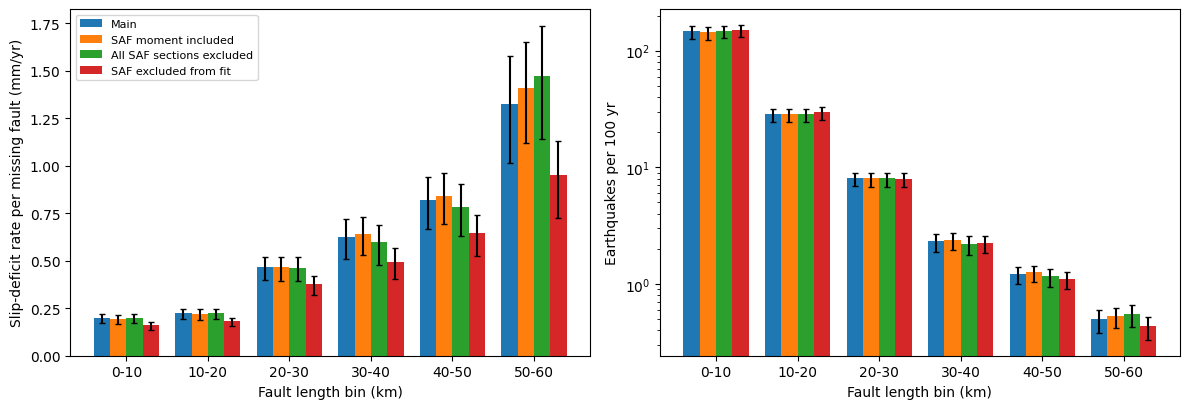

In [11]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
x = np.arange(6)
w = 0.2
for i, k in enumerate(out):
    for ax, var in zip(axs, ("slip", "eq")):
        best = out[k]["best"][var][:6]
        lo_, up_ = out[k]["lower"][var][:6], out[k]["upper"][var][:6]
        ax.bar(x + (i - 1.5) * w, best, w, yerr=[best - lo_, up_ - best], capsize=2, label=labels[k])
for ax, yl in zip(axs, ("Slip-deficit rate per missing fault (mm/yr)", "Earthquakes per 100 yr")):
    ax.set_xticks(x, bin_lbl)
    ax.set_xlabel("Fault length bin (km)")
    ax.set_ylabel(yl)
axs[1].set_yscale("log")
axs[0].legend(fontsize=8)
fig.tight_layout()
fig.savefig(SAF_OUT / "figures" / "saf_cases_per_bin.png", dpi=300, bbox_inches="tight")
plt.show()

## Main results

- **SAF lengths agree with the power law.** Power law predicts 1.9 traces longer than 550 km (2 observed), 3.6 for 300–550 km (3), 5.7 for 200–300 km (4) and 27.1 for 100–200 km (29). There is no length-based reason to remove them from the fit.
- **Removing them from the fit truncates the sample.** The refit gives $\alpha_l = 1.91$ (1.66–2.21), inside the main bootstrap interval (1.54–2.08). The truncated-likelihood estimate on the main range is 1.63, also inside it. The main value of 1.77 lies in the range of 1.3–1.8 that Zou & Fialko (2024) expect for $L > T$.
- **SAF moment rates do not follow the potency partition.** The two traces carry 32% of $M_{on}$, while the partition predicts 17% for faults longer than $L_{ref}$. Their equivalent slip rates are 11.9 and 10.6 mm/yr, against a median of 1.6 mm/yr for the other traces longer than 100 km. This is expected for a mature plate-boundary fault whose slip rate is set by plate motion, which is why they are excluded from the normalization.
- **The normalization choice barely affects the 0–30 km results.** Because the allocation is rescaled to $M_{off}$, the normalization only changes how the budget is shared among eligible bins.
  - Including the SAF moment changes the 0–30 km slip and earthquake rates by less than 2%, and the 30–60 km rates by up to 10%.
  - Also removing the SAF sections that sit in shorter traces (7.2% of $M_{on}$, mainly the Peninsula section) changes them by about 1% and up to 13%.
- **Excluding the SAF from the fit has a larger effect, but only on slip rates.** It steepens $\alpha_l$ and raises the number of missing faults by 27% (11,452 vs 9,017). Slip rates drop by about 20% for 0–30 km and 20–30% for 30–60 km. Earthquake rates change by less than 4% and 14%, because they depend only on the allocated moment.
- **Conclusions hold for every SAF treatment, as we discuss in our manuscript.**